# Qiskit Workshop

This notebook will walk you through how to use Qiskit's Sampler and Estimator frameworks in-depth through a series of practical exercises.

## Part 1: Installation

For local users, while we could just install everything by running a pip command in a codeblock, we can be a bit more organized and use virtual environments!

To set this up properly, we can run the following commands in your terminal:
1. ```python -m venv QiskitStuff```
2. ```source QiskitStuff/bin/activate``` for Linux/Mac or ```QiskitStuff\Scripts\activate``` for Windows
3. ```python -m ipykernel install --user --name qiskit-kernel --display-name "Python (Qiskit)"```

Now you can run your pip installs within this directory and it won't conflict with anything else.

Here are a few pip installs to start us off, but you can add more as needed.

```pip install 'qiskit[visualization]' qiskit-ibm-runtime qiskit-aer qiskit_qasm3_import"```

In [2]:
# For Colab Users or if you couldn't set up the virtual environment
!pip install 'qiskit[visualization]' qiskit-ibm-runtime qiskit-aer qiskit_qasm3_import

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 89.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 105.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6

## Part 2: Qiskit Account

This is optional to do for this notebook, but if you haven't already, you should make an IBM Quantum account at https://quantum.cloud.ibm.com. It might require you to enter credit card information but there shouldn't be any charges if you use the basic/Pay-As-You-Go plan. Afterward, you can make an instance which will allow you to use IBM's computers. We can then actually use it by setting up the account as shown below.

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

your_api_key = "" # your key, can use environment variables if you know how to for more security
your_crn = "" # copy-paste from instance

QiskitRuntimeService.save_account(
     channel="ibm_quantum_platform",
     token=your_api_key,
     instance=your_crn,
     name="something",
)

In [ ]:
# We can check if the account is saved properly and then use it as needed
service = QiskitRuntimeService(name="fallfest-2025")
print(service.saved_accounts())

## Part 3: Basics

You don't need to do anything here (it's mostly a repeat of the previous Qiskit tutorial), but I'm including it as a reference for any needed syntax.

In [1]:
# Do run this cell so your code works!
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import SparsePauliOp, DensityMatrix, state_fidelity
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorOptions
from qiskit.quantum_info import Statevector
from qiskit.quantum_info import Operator
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit_ibm_runtime import SamplerV2 as Sampler, EstimatorV2 as Estimator
from qiskit.circuit import Parameter, ParameterVector

# Useful python stuff
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.linalg import eigvalsh

### Creating a circuit

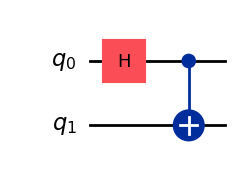

In [2]:
# Create a new circuit with two qubits
qc = QuantumCircuit(2)

# Add a Hadamard gate to qubit 0
qc.h(0)

# Perform a controlled-X gate on qubit 1, controlled by qubit 0
qc.cx(0, 1)
qc.draw("mpl")

In [3]:
output = Statevector(qc)
output.draw("latex") # Draw states in braket notation


<IPython.core.display.Latex object>

Before we continue with multiple qubits, let's stick to one qubit and visualize the rotations. Put some gates and then use the plot function below to see where your state ends up!

In [ ]:


# plot_bloch_multivector(output) # Draw bloch sphere for one qubit

### Classical Control

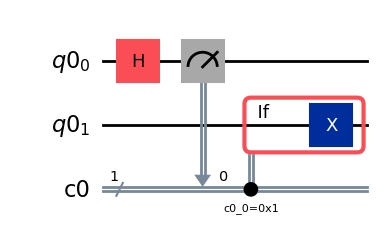

In [4]:
qubits = QuantumRegister(2)
clbits = ClassicalRegister(1)
qc = QuantumCircuit(qubits, clbits)

# Readability
(q0,q1) = qubits
(c0,) = clbits

qc.h(q0)
qc.measure(q0, c0)
with qc.if_test((c0, 1)):
    qc.x(q1)
#circuit.measure(q1, c0)
qc.draw("mpl")

### Measurement

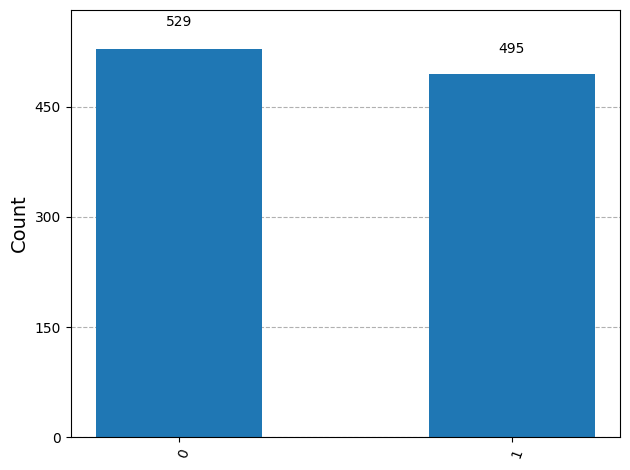

In [10]:
qubits = QuantumRegister(1)
qc = QuantumCircuit(qubits)

qc.h(0)
qc.measure_all()

# Specify backend for actual circuit computation
backend = AerSimulator()
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

# execute the quantum circuit
sampler = Sampler(backend)
job = sampler.run([isa_circuit])
result = job.result()

plot_histogram(result[0].data.meas.get_counts(), sort="asc")

## Part 4: Qiskit Frameworks

Now it's time for you to do stuff! Some of this section was from the tutorial, but it was towards the end and I think it's worth knowing properly.

### Sampler

The sampler, for a given state, gives the probability for every measurable state. It is only good for getting **sparse probability distributions** (state is expressible in a linear combination of bases with polynomial number of terms), as the sampler functions by running the circuit several times and measuring them, known as shots. It can be applied to a subsection of the circuit to only find a subset of states.

Let's start with the following:
1. Creates a quantum circuit that contains the |Φ+⟩ Bell state.
2. Uses the `measure_all` method to measure the results.
3. Transpiles the circuit using the `AerSimulator` backend.
4. Initializes the `Sampler` primitive with the `AerSimulator` backend
5. Runs the Sampler.
6. Gets the measurement counts.
7. Prints the measurement counts.

In [ ]:
# Refer to creating circuit and measurement in Part 2 if you're stuck

Let's make a *parameterized* circuit now, as commonly seen in variational algorithms.

1. Initialize a ParameterVector to store the needed parameters for your circuit (2 is enough but add as many as you like)
2. Create a two qubit circuit with rotation gates (Rx, Ry, Rz) with angles based on your ParameterVector (# of gates = len(ParameterVector))
3. Run **one** Sampler with *two* different choices of angles and display the counts

In [ ]:
# Most of it is the same as the first exercise
# Refer to sampler documentation if stuck on passing parameters (useful life skill!)
# can use plt.subplots to display the different results next to each other

## Estimator

The estimator, given an observable and state, finds the expected value of the observable. It does this by decomposing the observable into Pauli operators whose eigenbases are known, and creates a new operator $V$ to diagonalize the operator and measure its output (by running the circuit several times and sampling). It works efficiently for sparse Pauli decomposition, or that there are a polynomial number of nonzero weights. The premise of variational algorithms is based on optimizing expectation values of specific operators, so it is important to have a strong foundation with them.

The biggest difference between Sampler and Estimator in terms of software is creating our observables, which will be some series of gates.
Let's start by creating a few observables to work with. I suggest making a list of strings like "ZZ" (Z on both qubits) or "IX" (X on the second qubit) representing the desired gate sequences and then converting them into proper observables with ```SparsePauliOp```

In [ ]:
# Look up documentation as needed, but you are basically passing strings into SparsePauliOp

Now, let's make a Bell state circuit like we've done before

We then need to map our observables to our given circuit and then run Estimator. Instead of having counts, we will have numerical expectation values which we can plot as desired. Make a plot of the expectation values per observable.

In [ ]:
# Follow the same process with using the Aer backend to compile our circuit
# apply_layout will help map your observables which you will pass in when running the circuit
# you will want to plot result[0].data.evs against the list of observables strings


We can also do a more tangible example and consider $\langle \psi|Z|\psi \rangle$ as we rotate $|{\psi}\rangle$ along a great circle through the poles. Think about what the answer should be (maybe the image will help...? or use the matrix representations to compute it directly)

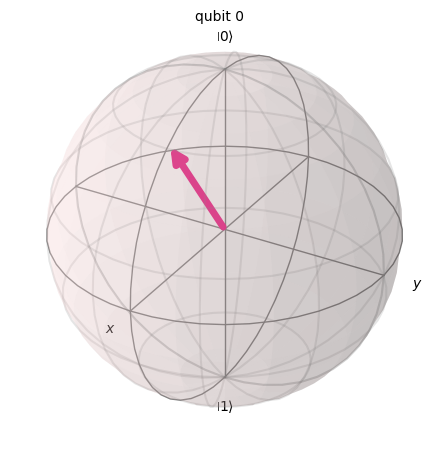

In [ ]:
qc = QuantumCircuit(1)
qc.ry(0.2*np.pi, 0)

output = Statevector(qc)
probs = output.probabilities_dict()
plot_bloch_multivector(output)

Plot the expectation value as $|{\psi}\rangle$ traverses the circle. You should find that the result is a simple function. For variational algorithms, we will want to find the minimum expectation value across the entire qubit(s), which will not be as a straightforward as sweeping through the parameter space as we did here.

In [ ]:
# HINTS:
# you only need a circuit with one parameterized gate
# think about how you describe a circle or how rotation gates work
# you can get all the data you need by running estimator only once, refer to sampler/documentation

### Bonus
Right now, we are only sweeping across one slice or degree of freedom in our qubit, but we know that arbitrary one-qubit states can be expressed with two degrees of freedom. With this in mind, find where the minimum expectation value of $\hat{H} = \hat{Z} + \hat{X}$ is by plotting the energy landscape with a heatmap.

# Part 5: Entanglement

You might think that entanglement is simply correlation, but it is a lot more weirder than that! Let's write some code to debunk this.


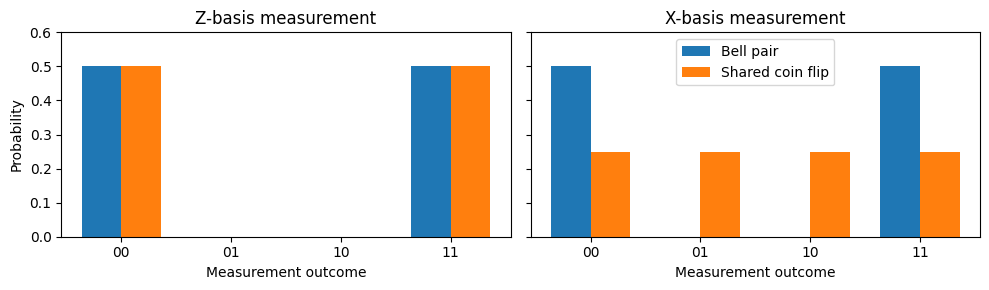

In [5]:
# Make a Bell ciricuit
# bell =

def probabilities(preparation, basis):
    qc = preparation.copy()
    # What gate shoudl you add if you change basis to "X"

    # Optionally, consider a "Y-basis measurement as well"

    return Statevector.from_instruction(qc).probabilities()

You can now run this to visualize the measurement outcomes. Think about why we get the results you do. Also consider what happens if you add additonal gates (like a Z).

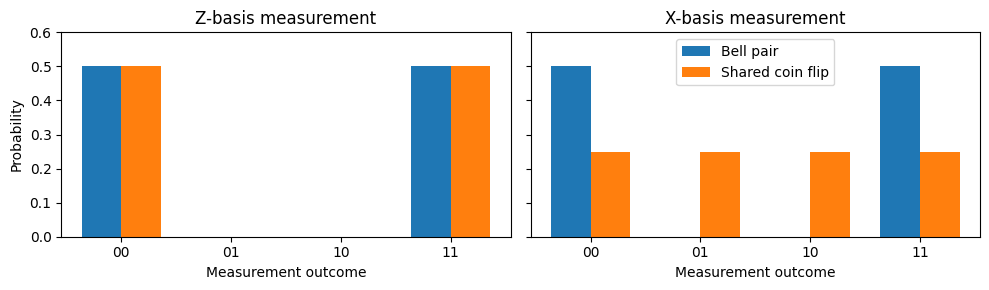

In [6]:
# Run this once you implement probabilities!

zero = QuantumCircuit(2)       # Prepare |00>
one = QuantumCircuit(2)        # Prepare |11>
one.x([0, 1])

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
positions = [0, 1, 2, 3]

for ax, basis in zip(axes, ["Z", "X"]):
    entangled = probabilities(bell, basis)

    # A fair coin chooses between the two preparations:
    classical = (
        probabilities(zero, basis) + probabilities(one, basis)
    ) / 2

    ax.bar([x - .18 for x in positions], entangled,
           width=.36, label="Bell pair")
    ax.bar([x + .18 for x in positions], classical,
           width=.36, label="Shared coin flip")
    ax.set_xticks(positions, ["00", "01", "10", "11"])
    ax.set_title(f"{basis}-basis measurement")
    ax.set_xlabel("Measurement outcome")
    ax.set_ylim(0, .6)

axes[0].set_ylabel("Probability")
axes[1].legend()
plt.tight_layout()
plt.show()

# Part 6: Quantum State Tomography

Now for an interesting application using both frameworks, we are tasked with characterizing our quantum states. Specifically, we want a metric for how close our given state created experimentally is to our target state to get a solid benchmark for how noisy our quantum computers are.

If you treat quantum states as vectors, then an intutive metric would be the dot product, which is simply $\langle \psi_{t}|\psi_{g} \rangle$. However, we won't have a good description of our given state due to the stochastic nature of errors, so the best we can do is to collect statistics on our state and encode them into the *density matrix*. For a two-qubit system, our quantum states look like $|\psi \rangle = \alpha|00 \rangle +\beta|01\rangle+\gamma|10\rangle+\delta|11 \rangle$, so our density matrix will be $$\rho = |\psi \rangle \langle \psi | = \begin{bmatrix}
|\alpha|^{2} & \alpha \beta^* & \alpha \gamma^* & \alpha\delta^* \\
\beta\alpha^* & |\beta|^{2} &  \beta\gamma^* & \beta\delta^* \\
\gamma \alpha^* & \gamma \beta^* & |\gamma|^{2} & \gamma\delta^* \\
\delta \alpha^* & \delta\beta^* & \delta\gamma^* & |\delta|^{2}
\end{bmatrix}$$

While the density matrix is defined in terms of an outer product of our given state, we can note that the diagonal terms are *populations*, or the probabilities of measuring a given basis state (hmmm what would be the perfect tool to find them...).

The off-diagonal terms are known as *coherences* and generally represent the quantum correlations in our state. They are bit more complicated to reason about and calculate directly, but we can extract them through measurement for some special cases. If you are interested, you can search parity oscillations to see how we can do measurements in different basis to recover Bell states.

Rather than bashing our heads over analytic manipulations, we can use the fact the the Pauli matrices form a basis for our density matrix, and we can find, based on orthogonality, that the coefficients are simply the expectation values of the the corresponding Pauli observables (I wonder what we can do here...)

We can then generalize our overlap metric to the fidelity, defined as $$\mathcal{F} = \langle \psi_t | \rho | \psi_t \rangle$$
It ranges from 0 to 1, and higher fidelities indicate less noise.

To start off with, suppose we were trying to recreate a Bell state:  

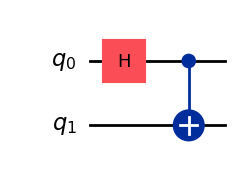

In [ ]:
target = QuantumCircuit(2)
target.h(0)
target.cx(0, 1)
target.draw("mpl")

But, our hardware introduced a few errors, which we will model as extraneous gates:

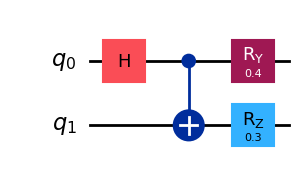

In [ ]:
target.ry(0.4, 0)
target.rz(0.3, 1)
true_dm = DensityMatrix(target)
target.draw("mpl")
# DONT MODIFY TARGET IN THE LATER CODE (at least until you finish the task, then you explore how the matrix changes with different errors)

To determine our noisy state, let's first calculate the populations directly.

In [ ]:
# Recall what populations represent
# You should make a new circuit based off of target, don't change target directly

Next, compute all the Pauli expectation values

In [ ]:
# You will need 15 observables (you don't need II, and later you can see how reducing the gate set impacts fidelity)

Now, reconstruct the density matrix with the following formula: $$\rho = \frac{1}{4} (II + \sum \langle P_i \rangle P_i)$$

After that, we should be done! For a sanity check, also display the eigenvalues of the density matrix and see if they are all positive (signifying physical probabilities).  

In [ ]:
# to_matrix and eigvalsh will be useful

Wait a minute! We have negative eigenvalues, so our density matrix is unphysical :(

This is due to the fact that Estimator will suffer from shot noise, so the measured coefficients won't be the exact expectation values and thus break our formula. To get around this, we can reconstruct our matrix in a more sophisticated form using the Cholesky decomposition. You can search up the details if interested, but to save time, I provided a helper function for you to use.

While this matrix form ensures the physicality of our density matrix, we can't directly convert our expectation values into such a matrix. Instead, we will optimize our Cholesky matrix to match our measured expectation values instead.

Finish the cost function provided below to minimze the mean squared error of both the expectation values and the populations of the density matrix.

In [ ]:
dim = 4  # 2-qubit system
def params_to_rho(params):
    """Cholesky parameterization: ensures ρ is PSD and Hermitian."""
    # params = [real diagonal (4), real off-diag (6), imag off-diag (6)] = 16
    T = np.zeros((dim, dim), dtype=complex)
    idx = 0
    for i in range(dim):
        for j in range(i + 1):
            if i == j:
                T[i, j] = params[idx]      # real diagonal
                idx += 1
            else:
                T[i, j] = params[idx] + 1j * params[idx + dim * (dim - 1) // 2]
                idx += 1
    rho = T.conj().T @ T
    return rho / np.trace(rho)

### CHANGE THIS ONLY
def cost(params):
    return

# Actual optimization after defining cost, no need to modify
x0     = np.random.rand(dim ** 2) * 0.1
result = minimize(cost, x0, method="L-BFGS-B", options={"maxiter": 5000})
rho_reconstructed = params_to_rho(result.x)

Let's check if this density matrix works as well, and then compute how close we are to the actual density matrix

In [ ]:
# use state_fidelity to compare density matrices together

Hooray! We did it! You can plot the matrix below in a nice manner if you would like (modifying it as needed)

In [ ]:
basis_labels = ["|00⟩", "|01⟩", "|10⟩", "|11⟩"]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

def plot_matrix(ax, matrix, title, vmax=0.6):
    im = ax.imshow(np.abs(matrix), cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(dim)); ax.set_xticklabels(basis_labels, fontsize=11)
    ax.set_yticks(range(dim)); ax.set_yticklabels(basis_labels, fontsize=11)
    ax.set_title(title, fontsize=13)
    plt.colorbar(im, ax=ax)
    for i in range(dim):
        for j in range(dim):
            ax.text(j, i, f"{np.abs(matrix[i,j]):.2f}",
                    ha="center", va="center", fontsize=10,
                    color="white" if np.abs(matrix[i,j]) > 0.3 else "black")

plot_matrix(axes[0, 0], true_dm.data,         "True ρ — magnitude")
plot_matrix(axes[0, 1], rho_reconstructed,     "Reconstructed ρ — magnitude")
plot_matrix(axes[1, 0], np.real(true_dm.data), "True ρ — real part", vmax=0.6)
plot_matrix(axes[1, 1], np.real(rho_reconstructed), "Reconstructed ρ — real part", vmax=0.6)

plt.suptitle(f"Variational State Tomography  |  Fidelity = {fidelity:.4f}", fontsize=14)
plt.tight_layout()
plt.show()

If you would like, you could switch out AerSimulator for an actual IBM computer backend and see how actual hardware noise impacts the results of what we've done so far.